# Prostate Patient_1 H2 — pan-cancer Hist2Pheno

Erickson et al. *Nature* 2022. Patient_1 series **H2**: H2_1, H2_2, H2_5 (3 sections). StarDist nuclei, **no cell-type ground truth**.
Sample ids are `Patient_1__H2_*`. Predictions are the pan-cancer **cross-section** checkpoint `D_emph_L2_spatial_pancancer` (L1 / L12 / L2), spatial k=8.

JPEG EXIF is 72 dpi and is not used. µm/px is the HEST-1k spot-spacing estimate, about **0.57–0.69**. UNI rescales by `mpp/0.5` so the 16 px crop is **8 µm**.

Patient_1 is split by series so each file stays small. The other series: `Pred_visual_prostate_patient1_H1.ipynb`, `_H2.ipynb`, `_V1.ipynb`. Patient_2 is `Pred_visual_prostate_patient2_{H1,…,V2}.ipynb`. Full-resolution PNGs stay in `data/Visium/Prostate/pred_pancancer_section/figures/`.

```bash
SAMPLE=Patient_1__H2 bash code/External_val/Prostate/demo.sh predict
```


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

REPO = Path("/home/lingyu/ssd2/Python/Hist2Pheno")
if not (REPO / "code").is_dir():
    REPO = Path("/nobackup2/users/lingyu/Python/Hist2Pheno")
sys.path.insert(0, str(REPO / "code" / "External_val" / "Prostate"))

from prostate_external import (  # noqa: E402
    PRED_ROOT,
    composition_table,
    discover_samples,
    geometry,
    sample_paths,
    ensure_l2_probs,
    plot_spatial,
    plot_composition,
)

PATIENT = "Patient_1"
SERIES = "H2"
group = discover_samples(f"{PATIENT}__{SERIES}")
fig_dir = PRED_ROOT / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)
# Re-run the plot cell after changing these. Notebook display uses DPI; saved PNGs use SAVE_DPI.
SAVE_FIGURES = False
FIGSIZE = (17.2, 6.6)
DPI = 160
SAVE_DPI = 300
HE_MAX_SIDE = 1400
MARKER_PX = 2.2
print(f"{PATIENT} {SERIES}  n={len(group)}")
for sample in group:
    g = geometry(sample)
    section = sample.split("__", 1)[-1]
    print(
        f"{section}  mpp={g['mpp_um']:.4f} µm/px  "
        f"native16={g['patch_um_if_native_16px']:.2f} µm  "
        f"after rescale={g['patch_um_after_rescale']:.1f} µm  "
        f"scale={g['scale']:.4f}  ({g['mpp_source']})"
    )
    pth = sample_paths(sample)
    print(f"  pred exists: {pth['pred'].is_file()}  {pth['pred']}")


Patient_1 H2  n=3
H2_1  mpp=0.5735 µm/px  native16=9.18 µm  after rescale=8.0 µm  scale=1.1470  (Visium scalefactors H2_1 (65 µm / spot_diameter_fullres=113.3410 px))
  pred exists: True  /nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/Patient_1__H2_1/Patient_1__H2_1_stardist_pred.h5ad
H2_2  mpp=0.5732 µm/px  native16=9.17 µm  after rescale=8.0 µm  scale=1.1465  (Visium scalefactors H2_2 (65 µm / spot_diameter_fullres=113.3889 px))
  pred exists: True  /nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/Patient_1__H2_2/Patient_1__H2_2_stardist_pred.h5ad
H2_5  mpp=0.5716 µm/px  native16=9.14 µm  after rescale=8.0 µm  scale=1.1431  (Visium scalefactors H2_5 (65 µm / spot_diameter_fullres=113.7250 px))
  pred exists: True  /nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/Patient_1__H2_5/Patient_1__H2_5_stardist_pred.h5ad


## Patient_1 H2 — spatial labels

[plot] Patient_1__H2_1  nuclei=177,710  neighbor=12.6px  figsize=(17.2, 12.54)  dpi=160  marker_px=2.2  rows=HE+points
[plot] Patient_1__H2_2  nuclei=183,086  neighbor=12.6px  figsize=(17.2, 12.54)  dpi=160  marker_px=2.2  rows=HE+points
[plot] Patient_1__H2_5  nuclei=334,112  neighbor=11.9px  figsize=(17.2, 12.54)  dpi=160  marker_px=2.2  rows=HE+points


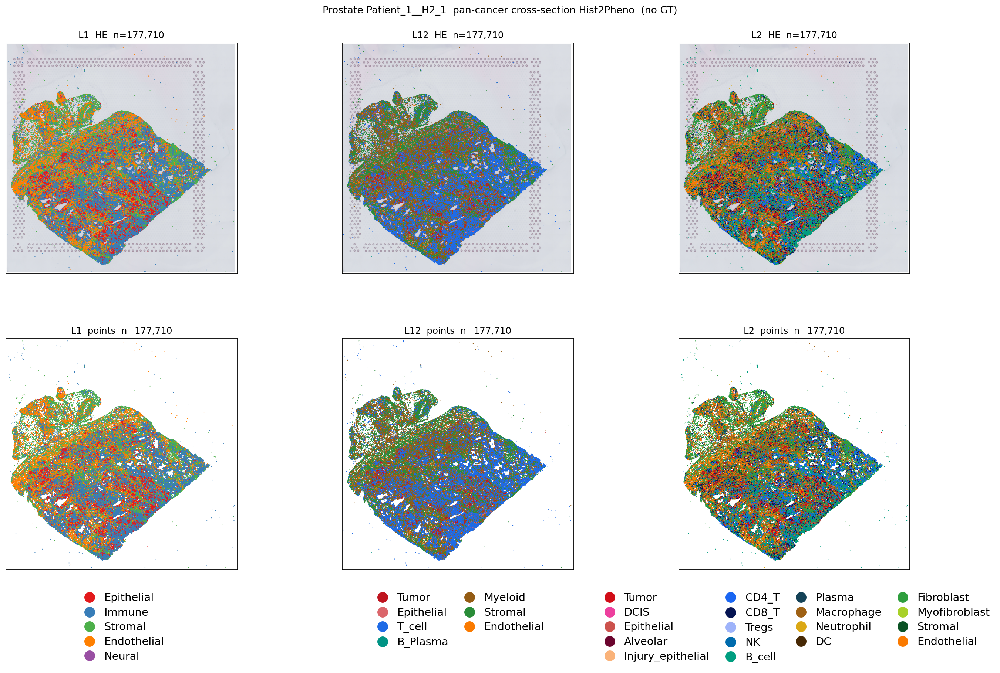

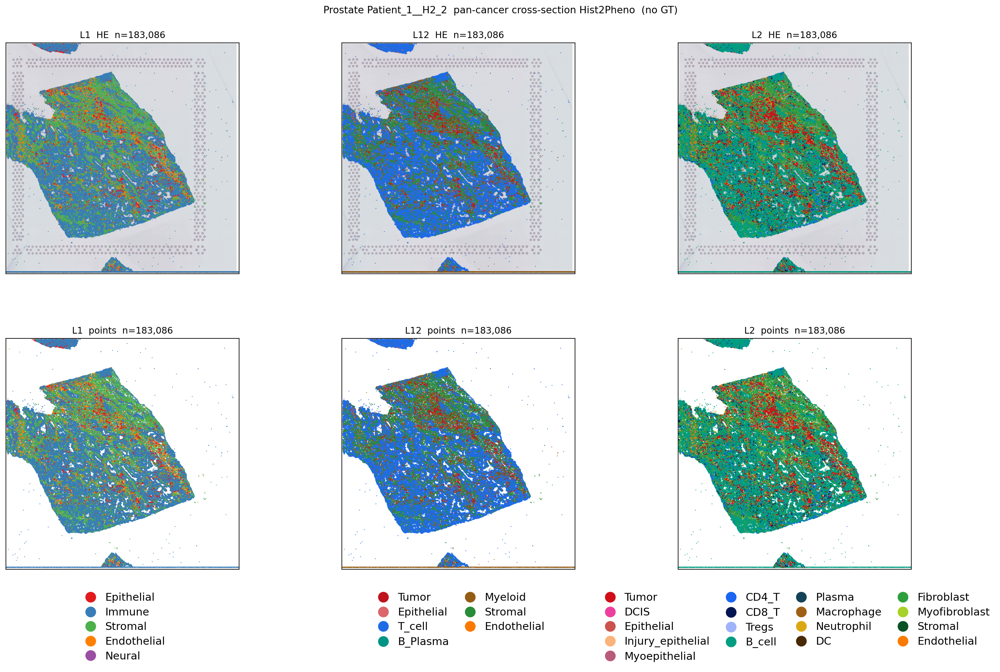

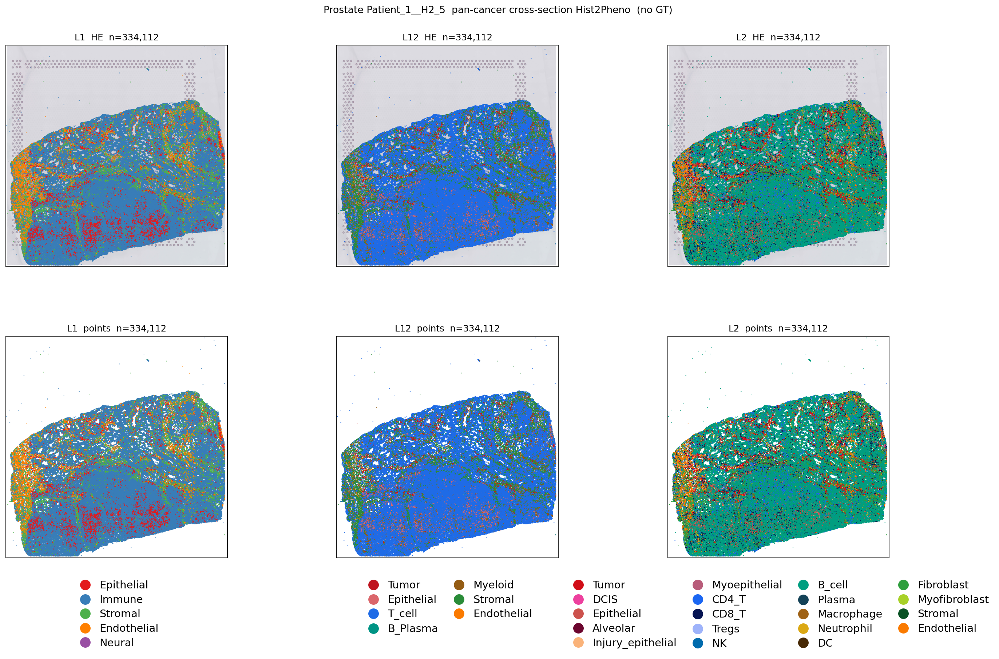

In [2]:
missing = [s for s in group if not sample_paths(s)["pred"].is_file()]
if missing:
    raise FileNotFoundError(
        f"No predictions yet for {PATIENT} {SERIES}: "
        + ", ".join(s.split("__", 1)[-1] for s in missing)
        + f". Run: SAMPLE={PATIENT}__{SERIES} bash code/External_val/Prostate/demo.sh predict"
    )

display(Markdown(f"## {PATIENT} {SERIES} — spatial labels"))
for fig in plot_spatial(
    group,
    figsize=FIGSIZE,
    dpi=DPI,
    he_max_side=HE_MAX_SIDE,
    marker_px=MARKER_PX,
    save=SAVE_FIGURES,
    save_dpi=SAVE_DPI,
):
    display(fig)
    plt.close(fig)


## Patient_1 H2_5 — spatial labels

[plot] Patient_1__H2_5  nuclei=334,112  neighbor=11.9px  figsize=(17.2, 12.54)  dpi=160  marker_px=0.8  rows=HE+points
[plot] /nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_1__H2_5_spatial_L1_L12_L2.png  save_dpi=300


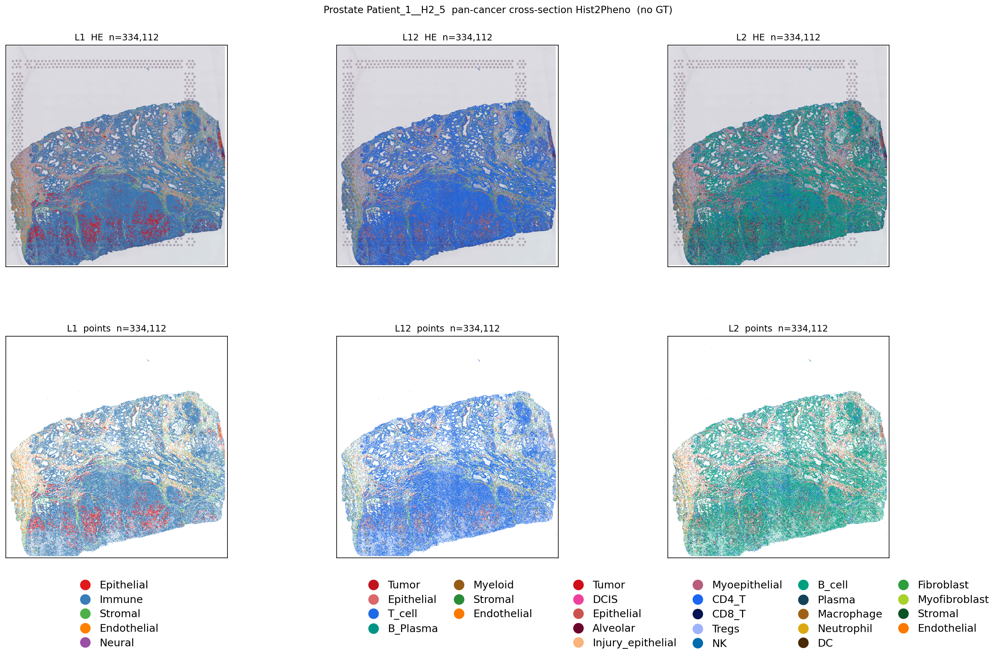

In [6]:
# Only Patient_1__H2_5 (keep the cell above for the full H2 series)
show = ["Patient_1__H2_5"]
missing = [s for s in show if not sample_paths(s)["pred"].is_file()]
if missing:
    raise FileNotFoundError(
        f"No predictions yet for {', '.join(missing)}. "
        f"Run: SAMPLE=Patient_1__H2_5 bash code/External_val/Prostate/demo.sh predict"
    )


SAVE_FIGURES = True
MARKER_PX = 0.8
display(Markdown("## Patient_1 H2_5 — spatial labels"))
for fig in plot_spatial(
    show,
    figsize=FIGSIZE,
    dpi=DPI,
    he_max_side=HE_MAX_SIDE,
    marker_px=MARKER_PX,
    save=SAVE_FIGURES,
    save_dpi=SAVE_DPI,
):
    display(fig)
    plt.close(fig)


## Patient_1 H2 — composition


===== Patient_1 H2 L1 =====


fraction               mean_conf                      n            \
section         H2_1   H2_2   H2_5      H2_1   H2_2   H2_5     H2_1      H2_2   
class                                                                           
Immune         0.542  0.740  0.803     0.531  0.650  0.672  96244.0  135481.0   
Endothelial    0.199  0.043  0.042     0.435  0.405  0.442  35411.0    7920.0   
Stromal        0.116  0.164  0.059     0.437  0.443  0.440  20603.0   29974.0   
Epithelial     0.143  0.053  0.096     0.517  0.499  0.589  25445.0    9707.0   
Neural         0.000  0.000  0.000     0.304  0.293  0.295      7.0       4.0   

                       
section          H2_5  
class                  
Immune       268420.0  
Endothelial   14027.0  
Stromal       19676.0  
Epithelial    31987.0  
Neural            2.0


===== Patient_1 H2 L12 =====


fraction               mean_conf                       n  \
section         H2_1   H2_2   H2_5      H2_1   H2_2   H2_5      H2_1   
class                                                                  
T_cell         0.594  0.733  0.839     0.498  0.533  0.539  105523.0   
Myeloid        0.205  0.063  0.027     0.353  0.332  0.342   36487.0   
Stromal        0.125  0.144  0.060     0.384  0.386  0.376   22127.0   
Tumor          0.051  0.045  0.017     0.484  0.467  0.459    9100.0   
Epithelial     0.007  0.005  0.034     0.400  0.470  0.503    1331.0   
B_Plasma       0.001  0.009  0.018     0.394  0.463  0.464     112.0   
Endothelial    0.017  0.001  0.004     0.330  0.305  0.320    3030.0   

                                 
section          H2_2      H2_5  
class                            
T_cell       134231.0  280392.0  
Myeloid       11521.0    8982.0  
Stromal       26387.0   20171.0  
Tumor          8227.0    5745.0  
Epithelial      841.0   11390.0  
B_Plasma       1632.0    5966.0  
Endothelial     247.0    1466.0


===== Patient_1 H2 L2 =====


fraction               mean_conf                      n  \
section               H2_1   H2_2   H2_5      H2_1   H2_2   H2_5     H2_1   
class                                                                       
B_cell               0.156  0.577  0.688     0.300  0.418  0.446  27767.0   
CD4_T                0.201  0.072  0.088     0.267  0.298  0.296  35736.0   
CD8_T                0.171  0.078  0.070     0.250  0.260  0.257  30320.0   
Fibroblast           0.129  0.150  0.056     0.251  0.256  0.252  22925.0   
Endothelial          0.115  0.015  0.024     0.233  0.221  0.243  20420.0   
Macrophage           0.096  0.010  0.003     0.203  0.171  0.174  17102.0   
Tumor                0.081  0.071  0.023     0.354  0.357  0.348  14321.0   
Epithelial           0.017  0.004  0.029     0.270  0.335  0.385   2967.0   
Neutrophil           0.008  0.016  0.004     0.175  0.211  0.207   1409.0   
Plasma               0.014  0.000  0.001     0.220  0.201  0.206   2461.0   
DC                   0.005  0.002  0.006     0.175  0.200  0.216    905.0   
Stromal              0.004  0.001  0.001     0.294  0.195  0.230    774.0   
Injury_epithelial    0.001  0.000  0.003     0.213  0.273  0.325     97.0   
Tregs                0.001  0.002  0.000     0.183  0.227  0.215    145.0   
Myofibroblast        0.002  0.000  0.000     0.189  0.183  0.165    287.0   
DCIS                 0.000  0.001  0.001     0.247  0.363  0.313     17.0   
NK                   0.000    NaN  0.000     0.211    NaN  0.174     55.0   
Myoepithelial          NaN  0.000  0.000       NaN  0.257  0.160      NaN   
Alveolar             0.000    NaN  0.000     0.158    NaN  0.171      2.0   

                                       
section                H2_2      H2_5  
class                                  
B_cell             105656.0  229947.0  
CD4_T               13197.0   29555.0  
CD8_T               14314.0   23231.0  
Fibroblast          27406.0   18770.0  
Endothelial          2714.0    8174.0  
Macrophage           1874.0    1102.0  
Tumor               13064.0    7814.0  
Epithelial            786.0    9677.0  
Neutrophil           2840.0    1295.0  
Plasma                 46.0     426.0  
DC                    318.0    2167.0  
Stromal                92.0     211.0  
Injury_epithelial      73.0    1158.0  
Tregs                 453.0     140.0  
Myofibroblast          30.0      70.0  
DCIS                  222.0     361.0  
NK                      NaN       5.0  
Myoepithelial           1.0       6.0  
Alveolar                NaN       3.0

[plot] /nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/composition_L1.png  save_dpi=300
[plot] /nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/composition_L12.png  save_dpi=300
[plot] /nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/composition_L2.png  save_dpi=300


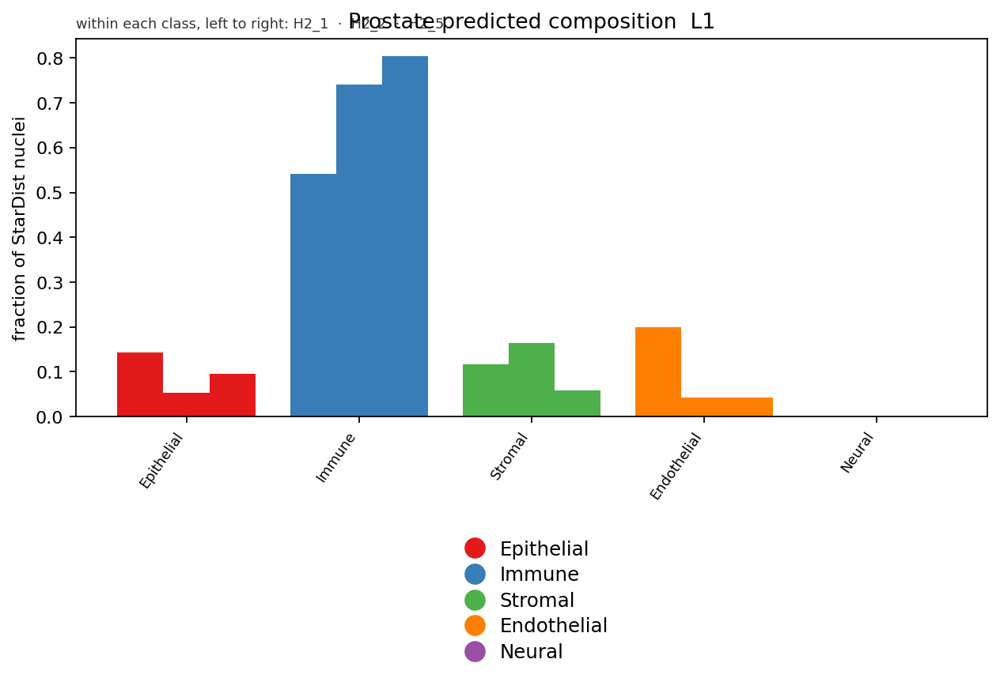

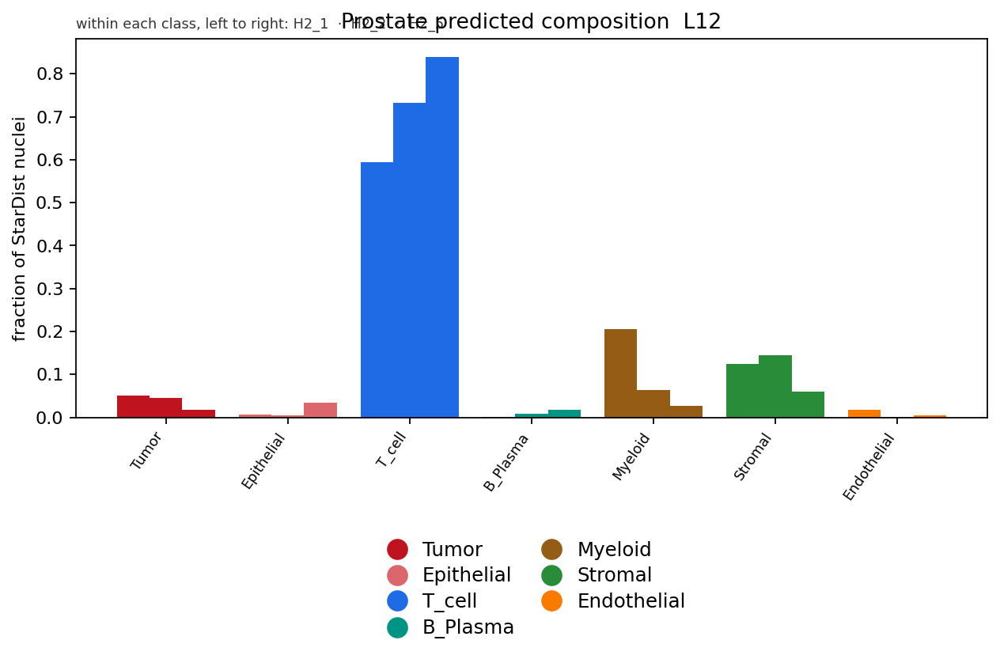

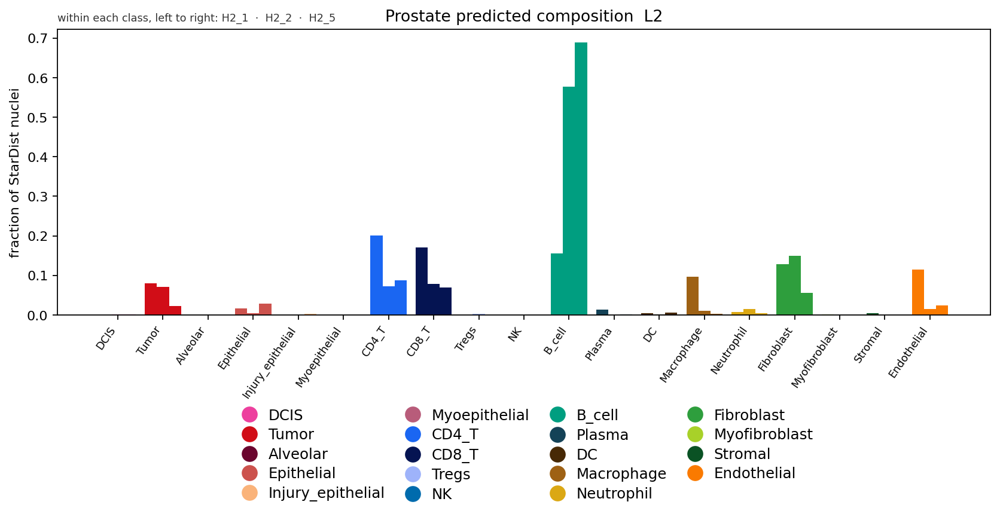

In [5]:
display(Markdown(f"## {PATIENT} {SERIES} — composition"))
comp = composition_table(group)
for head in ("L1", "L12", "L2"):
    sub = comp.loc[comp["head"] == head].copy()
    sub["section"] = sub["sample"].str.split("__").str[-1]
    order = sub.groupby("class")["fraction"].max().sort_values(ascending=False).index
    wide = (
        sub.pivot_table(index="class", columns="section", values=["fraction", "n", "mean_conf"])
        .reindex(order)
    )
    print(f"\n===== {PATIENT} {SERIES} {head} =====")
    display(wide.round(3))

for fig in plot_composition(group, save=SAVE_FIGURES, dpi=DPI, save_dpi=SAVE_DPI):
    display(fig)
    plt.close(fig)


## Histology-derived niche indices (TLS / SRI / TNI)

Same implementation as `code/Xenium_lung/histology_derived_niche_index.ipynb` §3, via `Hist2Pheno_pkg/histology_niche_index.py`. Lung ARI / FRI are not used.

Scores use **L2 softmax**, not the argmax label. `ensure_l2_probs` caches `{sample}_l2_probs.npz`.

| Index | Abundance | Spatial (radius R) |
|--|--|--|
| **TLS** | sum(B_cell + Plasma + CD4_T + CD8_T + Tregs + DC) | `(B_local × T_local × DC_local)^(1/3)` |
| **SRI** | (Fibroblast + Myofibroblast + Stromal) / epithelium | Fib_local / Epi_local |
| **TNI** | (fibroblast + Macrophage + Endothelial) / epithelium | `(Fib × Mac × Endo)^(1/3) / Epi_local` |

Epithelium = Epithelial, Tumor, Alveolar, Injury_epithelial, DCIS, Myoepithelial. NK is left out of TLS. `spatial_HE` is native JPEG pixels, so R = **55 µm** is converted with **that slide's** µm/px, not 0.5. TLS, SRI, and TNI each use a 1×3 row. Previews in this notebook are resized; the saved PNG is 300 dpi.


In [ ]:
import importlib

for _p in (REPO / "code" / "Hist2Pheno_pkg", REPO / "code" / "Xenium_lung"):
    if str(_p) not in sys.path:
        sys.path.insert(0, str(_p))

import histology_niche_index as hni
importlib.reload(hni)
import histology_derived_niche_index as hdni
importlib.reload(hdni)
from histology_niche_index import OrganNicheConfig

import anndata as ad

TLS_RADIUS_UM = 55.0
RECOMPUTE_NICHE = False

PROSTATE_NICHE = OrganNicheConfig(
    pan_organ="pancancer_prostate",
    tls_b=("B_cell", "Plasma"),
    tls_t=("CD4_T", "CD8_T", "Tregs"),
    tls_dc=("DC",),
    epithelium=(
        "Epithelial", "Tumor", "Alveolar",
        "Injury_epithelial", "DCIS", "Myoepithelial",
    ),
    fibroblast=("Fibroblast", "Myofibroblast", "Stromal"),
    endothelial=("Endothelial",),
    macrophage=("Macrophage",),
    um_per_he_pixel=float(geometry(group[0])["mpp_um"]),
    spatial_radius_um=TLS_RADIUS_UM,
    cohort="Prostate",
)
display(hni.index_formula_table(PROSTATE_NICHE))


In [ ]:
import numpy as np

missing = [s for s in group if not sample_paths(s)["pred"].is_file()]
if missing:
    raise FileNotFoundError(
        f"No predictions yet for {PATIENT} {SERIES}: "
        + ", ".join(s.split("__", 1)[-1] for s in missing)
        + f". Run: SAMPLE={PATIENT}__{SERIES} bash code/External_val/Prostate/demo.sh predict"
    )
display(Markdown(f"## {PATIENT} {SERIES} — TLS / SRI / TNI"))
frames = {}
for sample in group:
    paths = sample_paths(sample)
    niche_path = paths["pred"].with_name(f"{sample}_niche_indices.h5ad")
    mpp = float(geometry(sample)["mpp_um"])
    if niche_path.is_file() and not RECOMPUTE_NICHE:
        cached = ad.read_h5ad(niche_path)
        df = cached.obs.copy()
        xy = np.asarray(cached.obsm["spatial_HE"], dtype=np.float64)
        df["coord_x"] = xy[:, 0]
        df["coord_y"] = xy[:, 1]
        print(f"[niche] cache {niche_path.name}  n={len(df):,}  µm/px={mpp:.4f}")
    else:
        probs, class_names = ensure_l2_probs(sample)
        absent = hni.missing_index_cell_types(class_names, PROSTATE_NICHE)
        if absent:
            raise RuntimeError(f"{sample} missing niche compartments: {absent}")
        pred = ad.read_h5ad(paths["pred"])
        coords = np.asarray(pred.obsm["spatial_HE"], dtype=np.float64)
        df = pred.obs.copy()
        df["coord_x"] = coords[:, 0]
        df["coord_y"] = coords[:, 1]
        df = hni.add_abundance_indices(df, probs, class_names, PROSTATE_NICHE)
        df = hni.add_spatial_indices(
            df, probs, class_names, coords, PROSTATE_NICHE,
            radius_um=TLS_RADIUS_UM,
            um_per_pixel=mpp,
        )
        out = ad.AnnData(obs=df.drop(columns=["coord_x", "coord_y"]))
        out.obsm["spatial_HE"] = coords
        out.uns["tls_radius_um"] = TLS_RADIUS_UM
        out.uns["um_per_px"] = mpp
        out.write_h5ad(niche_path)
        print(f"[niche] wrote {niche_path}  n={len(df):,}")
    frames[sample] = df
    print(f"  TLS hotspot: {hni.summarize_tls_hotspots(df)}")
    print(
        f"  mean TLS={df['idx_TLS'].mean():.3f}  TLS_spatial={df['idx_TLS_spatial'].mean():.3f}  "
        f"SRI={df['idx_SRI_ratio'].mean():.3f}  TNI={df['idx_TNI_ratio'].mean():.3f}"
    )

def tls_score_row(df, sample: str) -> dict:
    a = df["idx_TLS"].to_numpy(dtype=float)
    s = df["idx_TLS_spatial"].to_numpy(dtype=float)
    a_hi = a >= np.percentile(a, 95)
    s_hi = df["tls_candidate"].fillna(False).astype(bool).to_numpy()
    inter = int(np.logical_and(a_hi, s_hi).sum())
    union = int(np.logical_or(a_hi, s_hi).sum())
    n_a = int(a_hi.sum())
    return {
        "sample": sample,
        "n": int(len(df)),
        "TLS_mean": float(np.mean(a)),
        "TLS_median": float(np.median(a)),
        "TLS_p95": float(np.percentile(a, 95)),
        "TLS_max": float(np.max(a)),
        "TLS_spatial_mean": float(np.mean(s)),
        "TLS_spatial_median": float(np.median(s)),
        "TLS_spatial_p95": float(np.percentile(s, 95)),
        "TLS_spatial_max": float(np.max(s)),
        "pearson": float(np.corrcoef(a, s)[0, 1]),
        "spearman": float(pd.Series(a).corr(pd.Series(s), method="spearman")),
        "top5_jaccard": (inter / union) if union else float("nan"),
        "abundance_top5_also_spatial_top5": (inter / n_a) if n_a else float("nan"),
        "TLS_spatial_mean_in_abundance_top5": float(s[a_hi].mean()) if n_a else float("nan"),
        "TLS_mean_in_spatial_top5": float(a[s_hi].mean()) if s_hi.any() else float("nan"),
    }

tls_quant = pd.DataFrame([tls_score_row(df, sample) for sample, df in frames.items()])
tls_quant.insert(1, "section", tls_quant["sample"].str.split("__").str[-1])
tls_quant_path = fig_dir / f"tls_score_summary_{PATIENT}_{SERIES}.csv"
tls_quant.to_csv(tls_quant_path, index=False)
print(tls_quant_path)
display(tls_quant.round(3))

for sample, df in frames.items():
    fig, axes = hdni.plot_tls_abundance_vs_spatial(
        df,
        sample,
        radius_um=TLS_RADIUS_UM,
        use_entropy=False,
        split_spatial_candidates=True,
        dpi=DPI,
        save_dpi=SAVE_DPI,
        point_size=0.15,
        candidate_size=1.2,
        save_path=(fig_dir / f"{sample}_TLS_abundance_vs_spatial.png") if SAVE_FIGURES else None,
    )
    display(fig)
    plt.close(fig)
    for abundance_col, spatial_col, candidate_col, tag in (
        ("idx_SRI_ratio", "idx_SRI_spatial", "sri_candidate", "SRI"),
        ("idx_TNI_ratio", "idx_TNI_spatial", "tni_candidate", "TNI"),
    ):
        fig, axes = hdni.plot_tls_abundance_vs_spatial(
            df,
            sample,
            radius_um=TLS_RADIUS_UM,
            abundance_col=abundance_col,
            spatial_col=spatial_col,
            candidate_col=candidate_col,
            score_name=tag,
            use_entropy=False,
            split_spatial_candidates=True,
            dpi=DPI,
            save_dpi=SAVE_DPI,
            point_size=0.15,
            candidate_size=1.2,
            save_path=(fig_dir / f"{sample}_{tag}_abundance_vs_spatial.png") if SAVE_FIGURES else None,
        )
        display(fig)
        plt.close(fig)
